In [ ]:
#| hide 
from SFCmodeler.term import Term, Variable, Parameter
from SFCmodeler.SFCmodel import SFCmodel
from SFCmodeler.modelresults import ModelResults


# SFCmodeler

> A lightweight Python solver for Post-Keynesian Stock-Flow Consistent (SFC) or other time-series models, built on top of Pandas and Sympy.

## Usage

### Installation

```sh
$ pip install SFCmodeler
```
(Doesn't work yet :)

Install latest from the GitHub [repository][repo]:

```sh
$ pip install git+https://github.com/slevey087/SFCmodeler.git
```

[repo]: https://github.com/slevey087/SFCmodeler
[docs]: https://slevey087.github.io/SFCmodeler/
[pypi]: https://pypi.org/project/SFCmodeler/
[conda]: https://anaconda.org/slevey087/SFCmodeler

Then import with 
```py
from SFCmodeler import *
```

### Documentation

Documentation can be found hosted on this GitHub [repository][repo]'s [pages][docs]. Additionally you can find package manager specific guidelines on [pypi][pypi].

[repo]: https://github.com/slevey087/SFCmodeler
[docs]: https://slevey087.github.io/SFCmodeler/
[pypi]: https://pypi.org/project/SFCmodeler/
[conda]: https://anaconda.org/slevey087/SFCmodeler

## How to use

First declare `Parameter`s (fixed exogenous values), `Variable`s (found endogenously by the solver), and any `Random` elements, each with a `name` and optional `description` and `initial_value`

In [ ]:
Variable.default_value = 10  # This sets a default initial value for Variables

C = Variable("C","Consumption")
T = Variable("T","Taxes")
V = Variable("V","Wealth",100)   # The number 100 overrides the default value declared above
Y = Variable("Y","GDP")

alpha1 = Parameter("alpha_1","MPC out of income",0.6)
alpha2 = Parameter("alpha_2","MPC out of wealth",0.4)
G = Parameter("G","Government spending",5)
theta = Parameter("theta","Tax rate",0.2)

Next define the `SFCmodel` with a list of equations. Each equation should have one variable on the LHS, then `<<` as the equals sign, then any valid `Sympy` expression:

In [ ]:
model = SFCmodel(
    [
        C << alpha1 * (Y - T) + alpha2 * V(-1),
        Y << C + G,
        T << theta * Y,
        V << V(-1) + Y - T - C
    ]
)

Run `.solve()` to solve one period forward, or specify a number of periods to solve more than one time step:

In [ ]:
model.solve(5)

  0%|          | 0/5 [00:00<?, ?it/s]

|      |     $C$ |   $G$ |     $T$ |      $V$ |   $V_{-1}$ |     $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|--------:|------:|--------:|---------:|-----------:|--------:|---------------:|---------------:|-----------:|
| 2000 | 10      |     5 | 10      | 100      |   100      | 10      |            0.6 |            0.4 |        0.2 |
| 2001 | 81.5385 |     5 | 17.3077 |  87.6923 |   100      | 86.5385 |            0.6 |            0.4 |        0.2 |
| 2002 | 72.071  |     5 | 15.4142 |  77.2781 |    87.6923 | 77.071  |            0.6 |            0.4 |        0.2 |
| 2003 | 64.0601 |     5 | 13.812  |  68.4661 |    77.2781 | 69.0601 |            0.6 |            0.4 |        0.2 |
| 2004 | 57.2816 |     5 | 12.4563 |  61.0098 |    68.4661 | 62.2816 |            0.6 |            0.4 |        0.2 |
| 2005 | 51.546  |     5 | 11.3092 |  54.7006 |    61.0098 | 56.546  |            0.6 |            0.4 |        0.2 |

Easily shock a model by changing a parameter value with this shortcut:

In [ ]:
model[alpha1] = 0.7

model.solve(5)

  0%|          | 0/5 [00:00<?, ?it/s]

|      |     $C$ |   $G$ |      $T$ |      $V$ |   $V_{-1}$ |     $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|--------:|------:|---------:|---------:|-----------:|--------:|---------------:|---------------:|-----------:|
| 2000 | 10      |     5 | 10       | 100      |   100      | 10      |            0.6 |            0.4 |        0.2 |
| 2001 | 81.5385 |     5 | 17.3077  |  87.6923 |   100      | 86.5385 |            0.6 |            0.4 |        0.2 |
| 2002 | 72.071  |     5 | 15.4142  |  77.2781 |    87.6923 | 77.071  |            0.6 |            0.4 |        0.2 |
| 2003 | 64.0601 |     5 | 13.812   |  68.4661 |    77.2781 | 69.0601 |            0.6 |            0.4 |        0.2 |
| 2004 | 57.2816 |     5 | 12.4563  |  61.0098 |    68.4661 | 62.2816 |            0.6 |            0.4 |        0.2 |
| 2005 | 51.546  |     5 | 11.3092  |  54.7006 |    61.0098 | 56.546  |            0.6 |            0.4 |        0.2 |
| 2006 | 56.0914 |     5 | 12.2183  |  47.4823 |    54.7006 | 61.0914 |            0.7 |            0.4 |        0.2 |
| 2007 | 49.5294 |     5 | 10.9059  |  41.5764 |    47.4823 | 54.5294 |            0.7 |            0.4 |        0.2 |
| 2008 | 44.1604 |     5 |  9.83208 |  36.7443 |    41.5764 | 49.1604 |            0.7 |            0.4 |        0.2 |
| 2009 | 39.7676 |     5 |  8.95352 |  32.7908 |    36.7443 | 44.7676 |            0.7 |            0.4 |        0.2 |
| 2010 | 36.1735 |     5 |  8.2347  |  29.5561 |    32.7908 | 41.1735 |            0.7 |            0.4 |        0.2 |

`.data` holds a `ModelResults` object, which is a fancy pandas `DataFrame` such that you can use your parameters and variables as indexers, or also calculated expressions, and also quickly plot:

In [ ]:
model.data[[Y, C(-1), alpha1*Y]]

|      |     $Y$ |   $C_{-1}$ |   $\alpha_{1} \cdot Y$ |
|:-----|--------:|-----------:|-----------------------:|
| 2000 | 10      |   nan      |                 6      |
| 2001 | 86.5385 |    10      |                51.9231 |
| 2002 | 77.071  |    81.5385 |                46.2426 |
| 2003 | 69.0601 |    72.071  |                41.436  |
| 2004 | 62.2816 |    64.0601 |                37.369  |
| 2005 | 56.546  |    57.2816 |                33.9276 |
| 2006 | 61.0914 |    51.546  |                42.764  |
| 2007 | 54.5294 |    56.0914 |                38.1705 |
| 2008 | 49.1604 |    49.5294 |                34.4123 |
| 2009 | 44.7676 |    44.1604 |                31.3373 |
| 2010 | 41.1735 |    39.7676 |                28.8214 |

<Axes: >

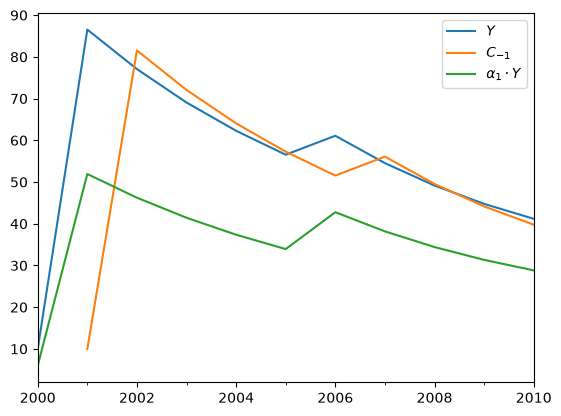

In [ ]:
model.data[[Y, C(-1), alpha1*Y]].plot()

See the other doc pages for more details and additional features.